# 09 优惠券管理：配置、发放、兑换码与异步生成

## 本章范围与资料来源

优惠券管理是运营后台的一条完整链路：**配置优惠券 → 待发放 → 立即或定时发放 → 暂停 / 结束 → 用户领取或兑换**。本章聚焦管理端、兑换码生成和发放状态；用户领取、并发核销、优惠叠加会在后续用户端章节展开。

| 来源 | 本章使用的内容 |
| --- | --- |
| [网盘分享](https://pan.baidu.com/s/1dcVvDI-sWN68Xzcsz1LSAQ?pwd=w7bj)，提取码 `w7bj` | `day09-优惠券管理/讲义/day09-优惠券管理.pptx`，共 43 页；核对优惠券模型、5 个 CRUD 接口、发放 / 暂停接口、兑换码位布局和异步生成流程；嵌入第 5、34 页原图 |
| 网盘 `day09-优惠券管理/资料` | 看到 `dto`、`enums`、`query`、`utils`、`vo` 目录和 `tj_promotion.sql`；`utils` 下有 `Base32.java`、`CodeUtil.java`。普通下载需要登录，因此笔记只把课件和可见预览作为已核对来源，不把未读附件当作源码引用 |
| [第三方公开转载：Day09-优惠券管理](https://imousse.github.io/cswiki/src/project/college/09-%E4%BC%98%E6%83%A0%E5%88%B8%E7%AE%A1%E7%90%86) | 补充服务结构、事务代码、线程池和兑换码工具的讲解；它是转载，遇到与原课件或可推导约束冲突的地方，以已核对材料和可执行约束为准 |

阅读日期：2026-10-09。**课件方案**表示材料明确展示的实现；**整理示例**是为了看懂主线而写的最小代码；**补充 / 改进示例**专门标出并发、重试、恢复和安全边界。本文所有单元格都是 Markdown，代码不会连接数据库、Redis、XXL-JOB 或课程服务。

## 先把业务边界说清楚

后台管理员先保存一张优惠券草稿，配置领取方式和时间窗，再把它发放出去。发放窗口决定“现在能不能被领取 / 兑换”，使用有效期决定“领到后什么时候能用”，两者不要混为一谈。

```text
新增
  ↓
待发放 ──立即发放──→ 进行中 ──暂停──→ 暂停
  │                     │              │
  └──定时发放→ 未开始 ───┘              └──再次发放──→ 进行中
                                  发放结束 / 定时结束
                                         ↓
                                        结束
```

暂停只阻止新的领取或兑换，不会自动撤销已经发给用户的券；结束通常表示领取窗口关闭，已领取优惠券是否还能使用仍要依据使用有效期和核销规则判断。兑换码优惠券第一次从“待发放”进入发放时生成码，暂停后恢复不能再次整批生成同一批码。

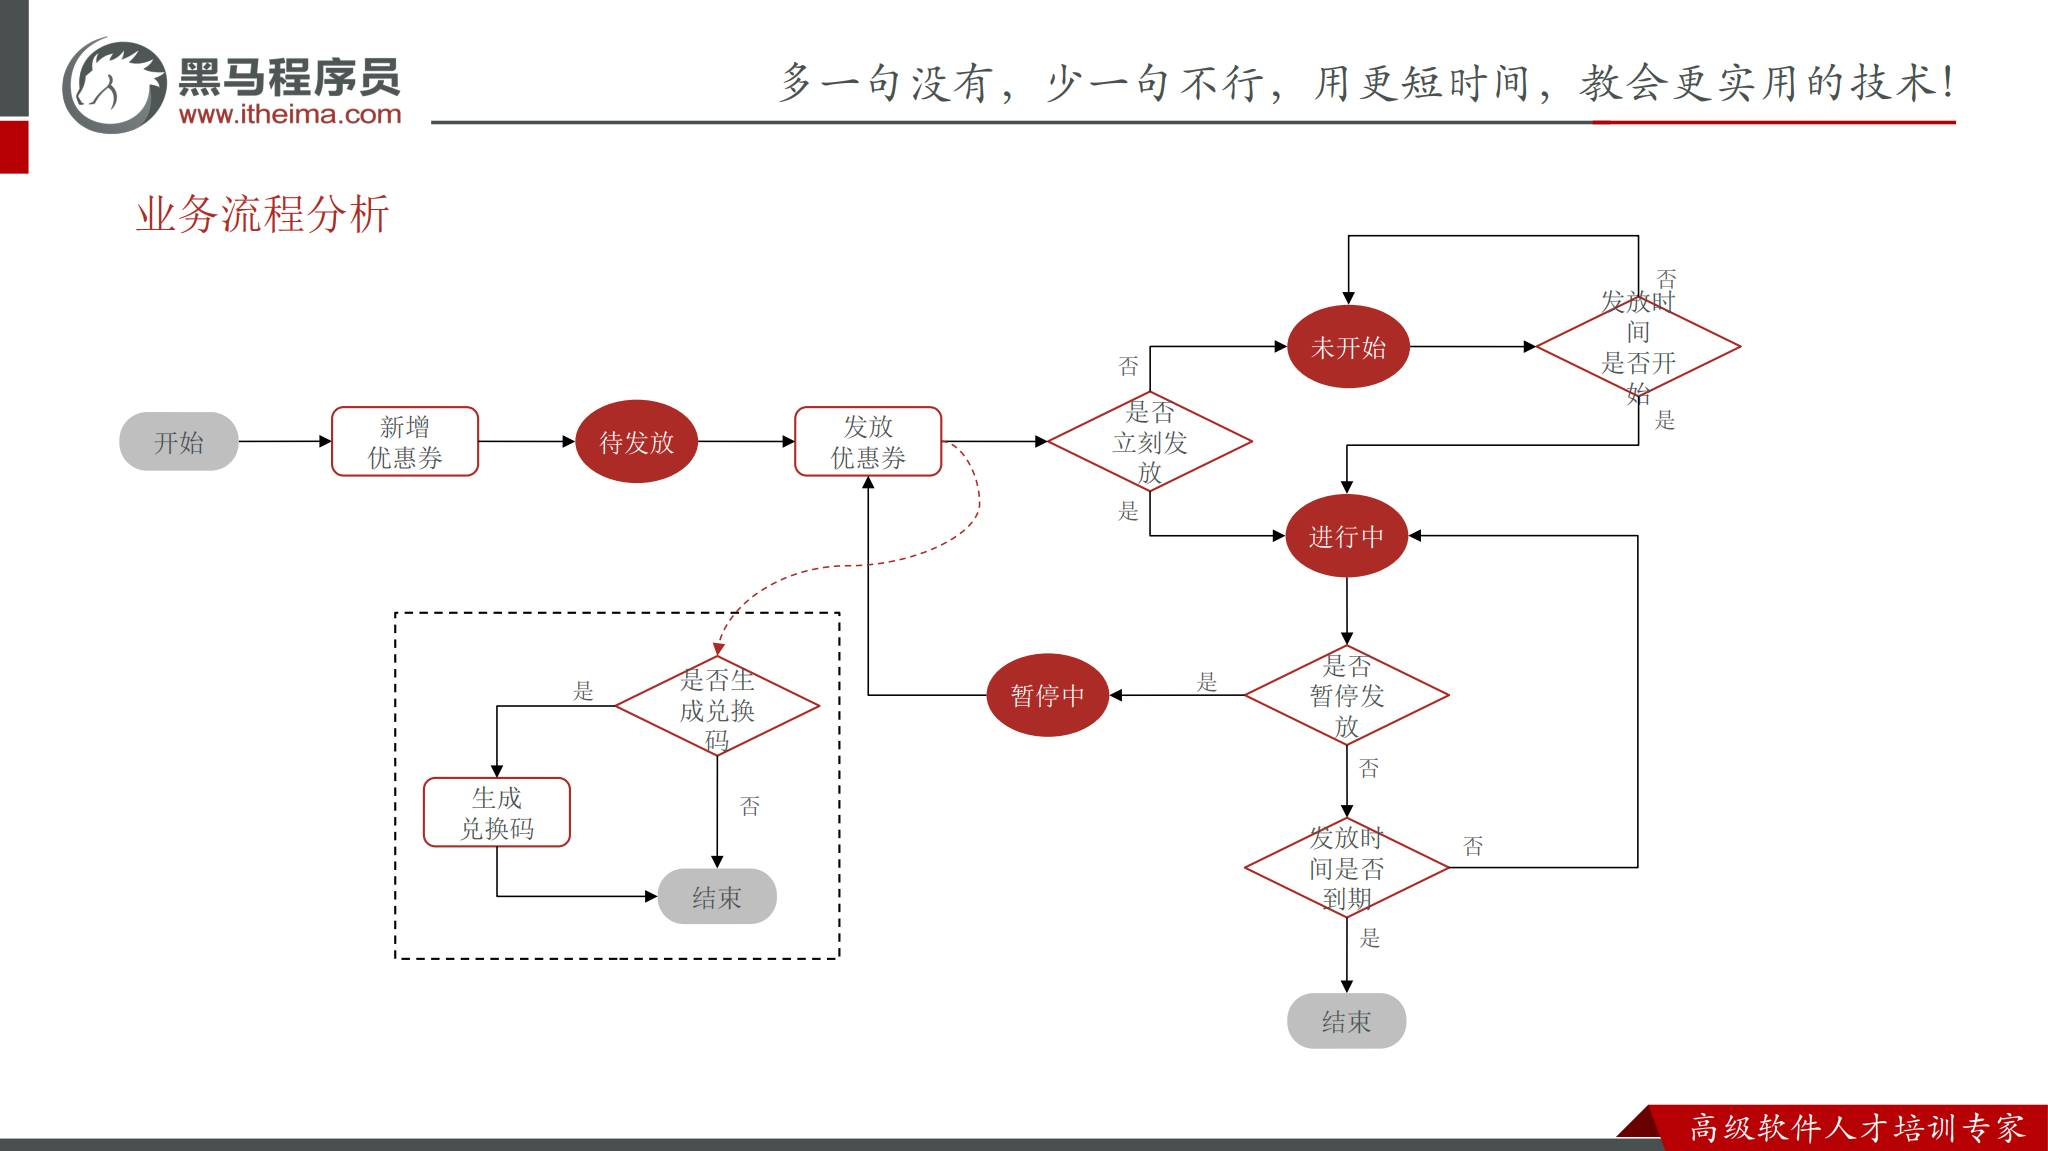

图源：网盘 `day09-优惠券管理.pptx` 第 5 页。图片随 Notebook 内嵌。

## 优惠券的领域模型

一张券既有营销规则，也有库存和生命周期。下面按课件表结构整理；金额单位在课件 DDL 中没有明确声明，示例只使用“统一整数金额单位”，不要擅自把它解释成元或分。

| 字段 | 含义 | 关键约束 |
| --- | --- | --- |
| `id`, `name` | 主键、名称 | `id` 自增；名称最长约 100 字符 |
| `discount_type` | 1 满减、2 每满减、3 折扣、4 无门槛 | 决定 `discount_value` 的解释 |
| `threshold_amount` | 使用门槛 | 0 表示无门槛 |
| `discount_value` | 减免金额或折扣值 | “8 折”示例是 80；不要把它当作 0.8 直接存入整数字段 |
| `max_discount_amount` | 优惠金额上限 | 0 表示无上限；是否适用于某类券要统一策略约定 |
| `specific` | 是否限定范围 | `true` 时必须有合法 `coupon_scope` |
| `obtain_way` | 1 手动领取、2 兑换码 | 代码中用枚举；不要依赖 DDL 的默认 0 |
| `total_num`, `issue_num`, `used_num` | 总量、已发给用户数、已使用数 | 课程总量上限 5000；`issue_num` 不是兑换码生成数量 |
| `user_limit` | 单用户可领数量 | 常见默认值为 1 |
| `issue_begin_time`, `issue_end_time` | 领取 / 兑换窗口 | 兑换码的到期时间使用此窗口的结束时间 |
| `term_begin_time`, `term_end_time`, `term_days` | 领到后的使用期限 | 固定时间段和领取后有效天数要互斥校验 |
| `status` | 1 草稿、2 未开始、3 进行中、4 结束、5 暂停 | 状态迁移必须在服务端校验 |
| `type`, `ext_param`, 创建 / 更新字段 | 业务类型与扩展 | `type` 是普通券等业务类型，不等于折扣类型 |

**整理示例**：满 100 减 15 可表示 `threshold_amount=100, discount_value=15`；满 200 打 8 折并封顶 50 还要设置 `max_discount_amount=50`。

## 限定范围为什么要单独一张表

一张优惠券可以覆盖多个分类或课程，一个分类也可能被多张券覆盖，这是多对多关系。因此用 `coupon_scope` 保存 `(coupon_id, type, biz_id)`，而不是把一串 ID 塞进 `coupon` 表。

| 场景 | `specific` | `coupon_scope` |
| --- | --- | --- |
| 全场券 | `false` | 没有范围行 |
| 指定分类券 | `true` | `type=1`，每个 `biz_id` 一行 |
| 未来扩展到课程 / 其他业务 | `true` | 用不同 `type` 区分 |

```java
// 整理示例：先校验，再在同一事务写入主表和范围表
if (Boolean.TRUE.equals(form.getSpecific())
        && (form.getBizIds() == null || form.getBizIds().isEmpty())) {
    throw new BadRequestException("限定范围不能为空");
}
Coupon coupon = BeanUtil.copy(form, Coupon.class);
save(coupon);
if (Boolean.TRUE.equals(coupon.getSpecific())) {
    List<CouponScope> scopes = form.getBizIds().stream().distinct()
        .map(id -> new CouponScope().setCouponId(coupon.getId())
            .setType(1).setBizId(id)).collect(Collectors.toList());
    scopeService.saveBatch(scopes);
}
```

源资料的保存片段容易漏掉 `type`；如果数据库字段是 `NOT NULL`，整理实现必须显式写入。`biz_id` 还要由服务端验证确实属于允许的分类 / 课程，不能只相信前端传来的数字。

## 优惠券与兑换码的关系

兑换码不是优惠券本身，而是可以指向某张券的一次领取凭证。课件中的核心关系是：一张券有很多兑换码，一个用户可以兑换多张券；`exchange_code.user_id` 记录实际兑换者，而不是预先绑定的收件人。

| 表 | 关键字段 | 作用 |
| --- | --- | --- |
| `coupon` | `id`, `obtain_way`, `issue_end_time` | 规则、总量和领取窗口 |
| `exchange_code` | `id`, `code`, `exchange_target_id`, `status` | 码文本、目标券、未使用 / 已兑换 / 活动结束 |
| `exchange_code` | `user_id`, `expired_time` | 谁兑换、何时失效；`expired_time` 对应领取窗口结束 |

课件 DDL 里 `exchange_code.id` 是有符号 `INT`，但算法又把它当作 32 位序列号。两者边界必须统一：有符号 `INT` 只能到 `2^31-1`；要覆盖完整 32 位序列，应改用 `BIGINT` 或明确 `INT UNSIGNED`，并在 Java 中使用 `long`。

## 三张表的约束与索引

课程数据库包含 `coupon`、`coupon_scope`、`exchange_code`。主键保证身份唯一，业务唯一约束保证重试时不会写出两份相同范围或码；索引决定管理端查询和定时任务是否能缩小扫描量。

| 表 | 已读转载 DDL 中的索引 | 可考虑的改进 |
| --- | --- | --- |
| `coupon` | 主键 `id` | 按任务查询增加 `(status, issue_begin_time)`、`(status, issue_end_time)` |
| `coupon_scope` | 主键、`idx_coupon(coupon_id)` | 对 `(coupon_id,type,biz_id)` 加唯一约束，禁止重复范围 |
| `exchange_code` | 主键、状态索引、目标券索引 | `code` 唯一索引；分页场景考虑 `(exchange_target_id,status,id)` |

```sql
-- 补充 / 改进示例：只展示设计，实际执行前先处理存量重复和实体类型
ALTER TABLE exchange_code MODIFY id BIGINT NOT NULL;
CREATE UNIQUE INDEX uk_exchange_code ON exchange_code(code);
CREATE UNIQUE INDEX uk_coupon_scope ON coupon_scope(coupon_id, type, biz_id);
```

DDL 中状态默认值不能替代合法状态机；`coupon.obtain_way` 默认 0 也不在定义的 1 / 2 枚举中，应由服务明确写入。`creater` 是转载 DDL 的实际拼写，代码生成与映射要一致；若重命名字段，必须连同所有使用方一起迁移。

## 优惠规则要先能解释，再谈实现

后台表单往往只保存数字，列表页和详情页要把数字解释成用户看得懂的文案。规则计算应集中在领域服务中，避免前端和后端各写一套。

| 类型 | 例子 | 计算直觉 |
| --- | --- | --- |
| 满减 | 满 100 减 15 | 订单满门槛后减固定金额 |
| 每满减 | 每满 100 减 10 | 按满足的完整门槛次数重复减 |
| 折扣 | 满 200 打 8 折，封顶 50 | 原价乘折扣，再应用最大优惠额 |
| 无门槛 | 直减 20 | 满足领取 / 使用资格即可减 |

```java
// 整理示例：Java 11；先校验金额非负、每满减门槛 > 0、折扣在 1..99
long discount;
switch (type) {
    case 1: discount = orderAmount >= threshold ? value : 0; break;
    case 2: discount = (orderAmount / threshold) * value; break;
    case 3: discount = orderAmount >= threshold
            ? orderAmount * (100 - value) / 100 : 0; break;
    case 4: discount = value; break;
    default: throw new IllegalArgumentException("未知优惠类型");
}
if (maxDiscount > 0) discount = Math.min(discount, maxDiscount);
discount = Math.min(discount, orderAmount); // 不超过本次可优惠金额
```

这里不展开优惠叠加、互斥和最优组合，那些属于用户使用 / 核销阶段。

## 促销服务的模块与基础配置

优惠券管理属于独立的营销领域。转载讲义从 `tj-promotion` 模块开始，服务名为 `promotion-service`，课程端口为 `8092`，数据库为 `tj_promotion`，Java 版本为 11。

| 依赖组 | 作用 |
| --- | --- |
| `tj-auth-resource-sdk`、`tj-api` | 登录拦截、项目公共客户端接口 |
| Web、MyBatis-Plus、MySQL | HTTP 接口和持久化 |
| Spring Data Redis、Redisson | 序列、范围缓存以及后续并发能力 |
| Nacos discovery / config、LoadBalancer | 服务发现、共享配置、客户端负载均衡 |
| Caffeine、XXL-JOB | 本地缓存依赖、分布式调度执行器 |

```yaml
# 课程配置关键项，部署地址、命名空间等由实际环境填写
server:
  port: 8092
spring:
  application:
    name: promotion-service
tj:
  jdbc:
    database: tj_promotion
  auth:
    resource:
      enable: true
```

启动类扫描 `com.tianji.promotion.mapper`；共享配置包括 spring、redis、mybatis、logs、feign、xxljob。课程 `dev` / `local` 的注册地址有环境差异，不能照抄演示 IP。根据三张表生成 PO、Mapper、Service、Controller，导入 DTO、Query、VO 和枚举。`specific` 字段遇到 SQL 关键字冲突时可用 `@TableField("`specific`")` 指定引用后的列名。材料中的创建分支、建库和启动命令是复现步骤，本次仅写笔记。

## 表单校验：把非法规则挡在落库前

前端控件限制能减少手误，后端校验才保证数据约束。新增、修改、发放的校验范围不同：草稿主要检查营销规则，发放额外检查领用时间。

| 参数组合 | 校验 |
| --- | --- |
| 名称与枚举 | 名称非空、长度受限；优惠类型、领取方式只接受定义值 |
| `totalNum`、`userLimit` | 课程 `1 <= totalNum <= 5000`；单人限领为正且不大于总量 |
| 满减 / 每满减 | 门槛、优惠值为正；每满减门槛不能为 0 |
| 折扣 | 按 100 为基数校验折扣；上限非负，零值解释统一 |
| 限定范围 | `specific=true` 则有非空合法 ID 集合；不限范围则不残留旧行 |
| 领取时间 | 结束时间必填且在未来；归一化后的开始早于结束 |
| 使用期限 | `termDays > 0` 与完整固定时间段二选一；固定开始早于固定结束 |

Bean Validation 的 `@NotNull`、`@Min` 等适合单字段约束；“二选一”“类型决定金额语义”等跨字段规则放在服务中。金额统一整数单位，乘法使用 `long`，舍入和可优惠金额范围由订单领域统一决定。后端强制初始状态和计数字段，避免批量属性复制接受不应由用户修改的值。

## 管理端接口总览

课件把接口分成优惠券 CRUD、发放控制、兑换码查询三组。路径中的 `{id}` 是资源 ID；请求体里的 ID 不能覆盖路径 ID。

| 能力 | 方法与路径 | 说明 |
| --- | --- | --- |
| 新增 | `POST /coupons` | 保存草稿，无返回体 |
| 分页 | `GET /coupons/page` | 按名称、折扣类型、状态筛选 |
| 详情 | `GET /coupons/{id}` | 编辑页需要附带范围明细 |
| 修改 | `PUT /coupons/{id}` | 主要修改草稿信息 |
| 删除 | `DELETE /coupons/{id}` | 只允许删除待发放 / 草稿 |
| 发放 | `PUT /coupons/{id}/issue` | 立即或定时开始 |
| 暂停 | `PUT /coupons/{id}/pause` | 只有进行中可暂停 |
| 兑换码分页 | `GET /codes/page` | 管理员查询码状态和目标券 |

删除接口在课件第 26 页明确是 `DELETE`；转载练习中把它抄成 `PUT` 属于笔误。

## 新增优惠券：主表与范围表必须原子提交

```java
// Controller：校验参数并调用 Service
@PostMapping
public void create(@RequestBody @Valid CouponFormDTO form) {
    couponService.saveCoupon(form);
}

// Service：事务覆盖主表和范围表
@Transactional
public void saveCoupon(CouponFormDTO form) {
    validateDraft(form);                 // 先校验，不让非法草稿落库
    Coupon coupon = BeanUtil.copy(form, Coupon.class);
    coupon.setStatus(CouponStatus.DRAFT);
    coupon.setIssueNum(0).setUsedNum(0);
    save(coupon);

    if (Boolean.TRUE.equals(form.getSpecific())) {
        List<CouponScope> scopes = form.getBizIds().stream().distinct()
            .map(id -> new CouponScope().setCouponId(coupon.getId())
                .setType(1).setBizId(id)).collect(Collectors.toList());
        scopeService.saveBatch(scopes);
    }
}
```

事务的目的不是“让两次写入更快”，而是保证主表成功而范围表失败时整体回滚。DTO 应白名单化，不接受前端直接设置 `status`、`issue_num`、`used_num` 等运营字段；`specific=true` 时范围为空、类型非法或范围重复都要在服务端拒绝。

## 分页查询：筛选条件和排序要稳定

课件的查询条件是 `pageNo`、`pageSize`、`type`、`status`、`name`。PPT 某页把 `name` 的类型写成了 `int`，而服务实现用 `StringUtils.isNotBlank(name)` 做模糊查询，所以 DTO 应使用 `String`。

```java
Page<Coupon> page = lambdaQuery()
    .eq(query.getType() != null, Coupon::getDiscountType, query.getType())
    .eq(query.getStatus() != null, Coupon::getStatus, query.getStatus())
    .like(StringUtils.isNotBlank(query.getName()), Coupon::getName, query.getName())
    .orderByDesc(Coupon::getCreateTime)
    .orderByDesc(Coupon::getId)       // 同一时间的记录也保持稳定
    .page(new Page<>(query.getPageNo(), query.getPageSize()));
```

课件默认每页 10 条、按创建时间倒序。空结果返回 `PageDTO.empty(page)`；非空结果把记录转为 `CouponPageVO`，再用 `PageDTO.of(page, records)` 保留总数等分页元数据。列表只需要展示 `specific` 等摘要字段，不要为每一行再查一次范围表；详情页再按券 ID 查询 `coupon_scope`。分页参数要限制上限，避免管理员传一个极大的 `pageSize` 拖垮数据库。

## 详情、修改、删除的状态约束

详情接口返回优惠券本体和范围 ID，供编辑页回显；修改和删除都要以数据库当前状态为准。

| 操作 | 允许状态 | 处理重点 |
| --- | --- | --- |
| 修改 | 草稿 | 更新主表，删除旧范围后批量写新范围，或做差量更新 |
| 删除 | 草稿 | 主表和范围表一起删除；有外键时按约束顺序处理 |
| 详情 | 任意存在状态 | 不因为状态不同而返回另一份规则 |

```java
// 整理示例：Controller 用 @DeleteMapping("/{id}") 调用此 Service
@Transactional
public void deleteDraft(Long id) {
    boolean deleted = remove(new LambdaQueryWrapper<Coupon>()
        .eq(Coupon::getId, id).eq(Coupon::getStatus, CouponStatus.DRAFT));
    if (!deleted) {
        throw new BadRequestException("只有草稿可以删除");
    }
    scopeService.remove(new LambdaQueryWrapper<CouponScope>()
        .eq(CouponScope::getCouponId, id));
}
```

示例沿用课程没有声明外键的表；若实际增加外键，要在锁定主记录并确认草稿后先删范围行。编辑也要以草稿条件更新或锁定主行，把状态校验、规则更新和范围替换放进同一事务，防止一边发布、一边改规则。

**面试提示**：状态校验不能只放在前端按钮上；任何调用方都能直接构造 HTTP 请求，服务端必须重新读取并校验状态。

## 发放接口：时间字段表达的是两套窗口

`PUT /coupons/{id}/issue` 的表单包含：

| 字段 | 含义 |
| --- | --- |
| `issueBeginTime`, `issueEndTime` | 用户领取或兑换的窗口 |
| `termBeginTime`, `termEndTime` | 固定使用有效期 |
| `termDays` | 从领取成功起算的有效天数 |

`termDays` 与固定 `termBeginTime/termEndTime` 应二选一；开始时间必须早于结束时间。若开始时间为空或已到，则进入 `ISSUING`；未来开始则进入 `UN_ISSUE`。发放接口只接受原状态为 `DRAFT` 或 `PAUSE` 的券。

路径 ID 要有唯一权威来源：

```java
@PutMapping("/{id}/issue")
public void issue(@PathVariable Long id,
                  @RequestBody @Valid CouponIssueFormDTO dto) {
    if (dto.getId() != null && !id.equals(dto.getId())) {
        throw new BadRequestException("路径 ID 与表单 ID 不一致");
    }
    dto.setId(id);
    couponService.beginIssue(dto);
}
```

课件示例的控制器没有显式绑定路径参数，整理实现补上了这层防护。

## 发放服务的处理顺序

下面保留转载服务的主要判断，生成任务的派发时机用文字说明。`now` 只取一次，避免同一请求两次时间判断跨过临界点。

```java
Coupon old = getById(dto.getId());
if (old == null) throw new BadRequestException("优惠券不存在");
CouponStatus oldStatus = old.getStatus();
if (oldStatus != CouponStatus.DRAFT && oldStatus != CouponStatus.PAUSE) {
    throw new BadRequestException("当前状态不可发放");
}
LocalDateTime now = LocalDateTime.now();
LocalDateTime begin = dto.getIssueBeginTime();
boolean immediate = begin == null || !begin.isAfter(now);
if (immediate) begin = now;
// 先校验 issueEndTime > begin 和完整使用期限，再写入
CouponStatus target = immediate ? CouponStatus.ISSUING : CouponStatus.UN_ISSUE;
boolean needCodes = oldStatus == CouponStatus.DRAFT
        && old.getObtainWay() == ObtainType.ISSUE; // 课程枚举：兑换码获取
```

原片段随后复制表单、更新券，并直接调用 `codeService.asyncGenerateCode(coupon)`；由于传入的是旧实体，还要把新 `issueEndTime` 带给生成器，否则兑换码会使用旧截止时间。整理实现更适合提交后传 `runId`，后台读取已经提交的新时间与固定生成参数。

恢复发放允许修改领取截止时间时，旧码的 `expired_time` 怎么处理必须有明确政策：冻结原批次截止时间、同步调整仍未兑换的旧码，或以券窗口为权威并统一校验。不能只改券表就假设所有旧码已延期。

## 发放状态迁移与并发边界

```text
DRAFT ──立即──→ ISSUING ──暂停──→ PAUSE
  │                │                 │
  └─定时→ UN_ISSUE ─┘                 └─再次发放→ ISSUING / UN_ISSUE

ISSUING / UN_ISSUE ──领取窗口结束──→ FINISHED
```

**课件方案**的服务步骤是：查询券 → 判断旧状态 → 根据 `issueBeginTime` 设置新状态 → 更新券 → 若旧状态是 `DRAFT` 且领取方式为兑换码，则异步生成第一批码。**补充 / 改进示例**应使用条件更新或锁防止两个管理员同时发放：

```sql
UPDATE coupon
SET status = :new_status, issue_begin_time = :begin_time,
    issue_end_time = :end_time, update_time = NOW()
WHERE id = :id AND status = :observed_status; -- observed_status 已校验为 1 或 5
```

条件最好使用 `status = :observed_status` 或乐观锁 `version = :observed_version`，保证后续生成判断对应的正是这次迁移。检查影响行数为 0 时重新读取并报告“状态已变化”。否则两个请求都可能读到旧状态并重复派发任务。暂停恢复即使前一次状态变回 PAUSE，也要由唯一批次键阻止首次生成任务重建。

## 定时发放与暂停

定时券需要在开始时间把 `UN_ISSUE` 改为 `ISSUING`，在结束时间关闭新的领取 / 兑换。课程使用 XXL-JOB 处理定时任务；任务应该按状态和时间建立索引并分片，不要每次扫描整张优惠券表。

| 任务 | 条件 | 动作 |
| --- | --- | --- |
| 开始任务 | `status=UN_ISSUE` 且 `issue_begin_time <= now < issue_end_time` | 条件更新为 `ISSUING` |
| 结束任务 | 领取窗口已结束且不是草稿 / 已结束 | 将本应结束的状态条件更新为 `FINISHED` |
| 暂停接口 | `PUT /coupons/{id}/pause` 且当前为 `ISSUING` | 更新为 `PAUSE` |

执行器重试时要再次检查状态和时间，不能把已经暂停的券强行改回进行中；如果任务延迟到窗口已经过去，也不应激活已经过期的券。结束任务还要覆盖漏过开始执行的 `UN_ISSUE`；对到期的 `PAUSE` 是否归为结束，应统一产品规则。本章改进约定三种状态都在窗口结束时归为 `FINISHED`，不覆盖草稿。暂停是停止新领取的运营动作，不等同于回收已发给用户的券。

## 兑换码为什么不能直接用 UUID

课件给兑换码提出六个目标：可读、容量大、不重复、可判断已兑换、防爆刷、高效。UUID 是 128 位，雪花 ID 通常是 64 位，都无法在 10 个字符的 32 进制空间中无损容纳；直接截断会损失唯一性。

课程使用不易混淆的 32 字符表：

```text
ABCDEFGHJKLMNPQRSTUVWXYZ23456789
```

去掉了 `I/O/0/1`，每个字符携带 5 bit，10 个字符最多 50 bit。算法布局为 `14 bit 校验/混淆信息 + 4 bit fresh + 32 bit 序列号`。Base32 只是编码，不是加密；它把数字变成字符，并不能防止猜测。

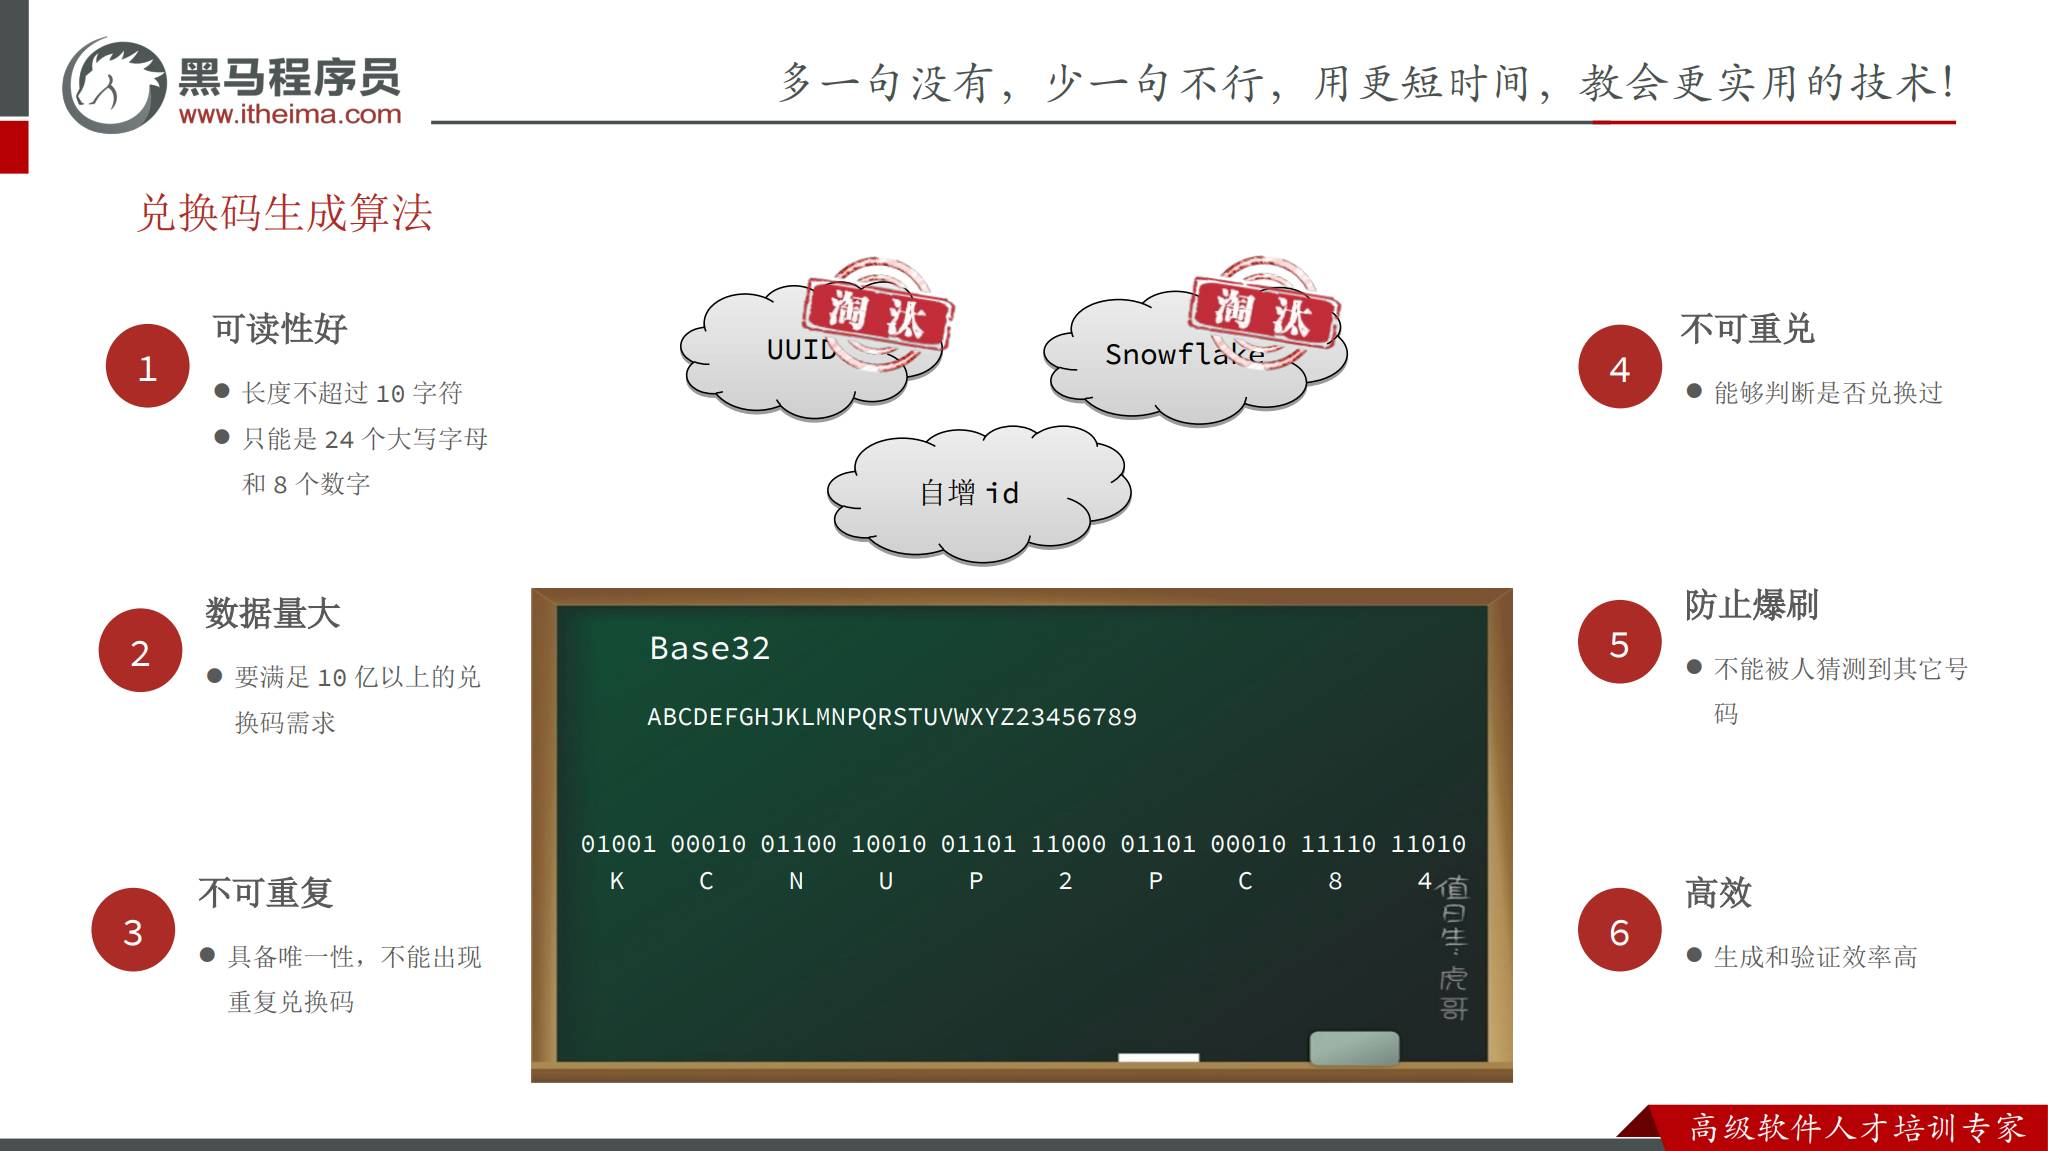

图源：网盘 `day09-优惠券管理.pptx` 第 34 页。图片随 Notebook 内嵌。

## 兑换码的位预算与课件示例核对

兑换码主体可以表示为：

```text
高 14 bit：check
中  4 bit：fresh（课程示例取 couponId 的低 4 位）
低 32 bit：serial（Redis 全局递增序列）
```

课件二进制例子写成 `01001 00010 01100 10010 01101 11000 01101 00010 11110 11010`，按给定字母表逐组映射时，第 4 组索引 18 对应 `U`，所以可核对结果是 `KCNUP2PC84`，与原 PPT 第 34 页一致；转载讲义中的 `KCNBP2PC84` 是映射笔误。不要把这个示例字符串当作业务固定码。

`fresh` 不是时间戳，也不是随机强度来源；它只是参与校验 / 混淆的 4 位上下文。真正把兑换码绑定到哪张券，仍要通过数据库中的 `exchange_code.exchange_target_id` 查询。

## 生成兑换码：顺序要与解析完全相反

以下是根据课件与已读转载工具代码整理的伪代码。网盘工具附件没有取得全文；常量表是实现细节，不在笔记中复制。

```java
String generateCode(long serial, long couponId) {
    if (serial < 1 || serial > 0xFFFFFFFFL) throw new IllegalArgumentException("序列越界");
    long fresh = couponId & 0xF;                 // 4 bit
    long payload = (fresh << 32) | serial;      // serial 先校验 <= 0xFFFFFFFF
    long check = calcCheck(payload, (int) fresh) & 0x3FFF; // 14 bit

    // 用 check 的低 5 bit 选择 32 项 XOR 表，混淆 36 位 payload
    payload ^= XOR_TABLE[(int) (check & 0x1F)];
    long codeNumber = (check << 36) | payload;
    return Base32.encode(codeNumber);
}
```

转载工具代码的 `calcCheckCode` 会按 4 bit 分块乘权相加再截取校验位；实际输入是 `fresh + serial` 共 36 位，最多 9 组，每行权重表至少覆盖 9 组。注释写“最后 13 位”与实际 14 位掩码不一致，整理时以位布局和掩码为准。XOR 只作用于低 36 位载荷，选择索引是校验值低 5 位、共 32 项，不是 16 项。生成前必须检查序列没有越过 32 位范围，不能用位掩码静默截断溢出。

## 加权校验和为什么能反解、却不能证明安全

按 4 位从低到高拆分载荷，每组数值为 0～15，乘权重后求和，保留低 14 位。`fresh` 选择哪一行权重；XOR 的索引来自保留在高位的 `check`，所以解析器先读取它，就知道如何还原载荷。

```java
// 整理示例：表内容省略；权重表每行至少 9 项
long calcCheck(long payload, int fresh) {
    int[] weights = PRIME_TABLE[fresh];
    long sum = 0;
    for (int i = 0; i < 9; i++) {
        sum += (payload & 0xF) * weights[i];
        payload >>>= 4;
    }
    return sum & 0x3FFF;
}
```

若遗漏 `fresh` 那一组，生成和验证就不再是展示代码里的同一规则。权重是质数也不会使线性求和变成 HMAC；公开表、XOR 和重新计算校验仍是公开可计算的过程，不能以“只有系统能算出校验值”解释防伪能力。

唯一性来自不复用的序列和可逆编码：XOR 再做一次就还原，Base32 可以反解；若两个码相同，它们的 `check` 和混淆载荷相同，还原出的序列也相同。换表或改编码会改变这个推理的版本条件，旧码需保持对应解析版本。

## 解析与验证：格式有效不等于已发行

```java
// 这里约定固定补齐 10 字符；实际附件编码 / 正则须配套核对
long parseCode(String text) {
    requireMatches(text, "[ABCDEFGHJKLMNPQRSTUVWXYZ23456789]{10}");
    long number = Base32.decode(text);
    long payload = number & ((1L << 36) - 1);
    int check = (int) (number >>> 36);
    payload ^= XOR_TABLE[check & 0x1F];
    int fresh = (int) ((payload >>> 32) & 0xF);
    if (calcCheck(payload, fresh) != check) throw invalid();
    return payload & 0xFFFFFFFFL; // serial
}
```

解析成功只说明字符、位布局和校验对得上。课件限制“长度不超过 10”，固定 10 位补齐是整理约定，未读取的 `Base32.java` 和正则附件不能据此推定。兑换流程还必须查询数据库确认：这个序列对应的兑换码确实存在、目标券匹配、状态未使用、领取窗口未结束、用户满足领取限制，并在成功兑换时原子地把状态改成已兑换。公开的固定表和 14 位校验值不能提供密码学认证。

## 序列号、Redis 自增与容量边界

课程使用 Redis `INCRBY`（一次增加 `total_num`）取得一段序列号，再批量生成兑换码。序列号服务必须是全局、单调且不复用的；允许因为失败而产生空洞，但不能重置后复用旧区间。

| 设计点 | 需要明确 |
| --- | --- |
| 类型 | Java 用 `long`，数据库用 `BIGINT` 或明确的 `INT UNSIGNED` |
| 上界 | 32 bit 无符号最大值是 `2^32-1`；Java `Integer.MAX_VALUE` 只有 `2^31-1` |
| 重启 | 计数器要持久化，恢复时不能回退到旧值 |
| 批次 | 保存 `couponId + serialStart + serialEnd + runId`，便于重试和审计 |
| 溢出 | 达到上界时停止发码并报警，不能 `serial & 0xFFFFFFFF` 静默回绕 |

兑换码数量达到几十亿时，长度 10 的结构仍受总位数限制；更高容量应改为更长的码或重新评估业务方案。

## Bitmap 只适合记录“序列是否用过”

用 Redis Bitmap 的一个 bit 表示一个序列号：`0` 表示未兑换，`1` 表示已兑换。完整 32 位空间是 `2^32 bit = 512 MiB`，而且高位序列可能让 Redis 分配从 0 到该偏移的空间，不能忽略稀疏高 offset 的成本。

```redis
GETBIT coupon:code:used {serial}
SETBIT coupon:code:used {serial} 1
```

Key 是整理示例，非已核对的源常量。全球序列使用一个 Bitmap 时最大 512 MiB；若按券分 Key 却仍使用全球 offset，空间还会重复膨胀。`GETBIT` 后再 `SETBIT` 存在并发竞态；单次 `SETBIT` 返回旧值，或 Lua 可原子地占用位，但不能连同 MySQL 发券事务一起提交。数据库条件更新 / 唯一约束才保障持久兑换状态，Redis 与数据库之间另需补偿。Bitmap 丢失、数据库写入失败、消息重试都需要恢复策略；Bitmap 不能替代 `exchange_code` 的持久状态。

## 兑换码的安全边界

校验和、XOR 混淆、不可读的字符表可以减少手误和明显的顺序暴露，但它们不是加密，也不是防伪签名。10 个字符的 50 bit 空间中，固定 32 bit 序列后，真正可用于上下文和校验的空间很有限。

| 方案 | 优点 | 局限 |
| --- | --- | --- |
| 课程结构码 | 快、短、可反解序列 | 表公开后可分析；14 bit 校验只能提供有限猜测阻力 |
| 随机 token + 数据库唯一索引 | 码与业务完全不透明 | 需要保存完整映射和索引 |
| 带截断 HMAC 的结构码 | 服务端密钥可鉴别修改 | 标签位数决定猜测阻力；仍需长度、限流和密钥轮换设计 |

14 bit 校验只有 16384 种值，不能把它当作强认证标签。10 字符保留 32 bit 序列后，其余 18 bit 还要分配上下文与校验，强度存在硬上限；增加长度通常更直接。生产接口还应做尝试频率限制、失败计数、管理员权限隔离和审计；算法通过不代表码已经被发行。更换表或密钥须设计版本和旧码兼容，不能定期换表后使全部旧码失效。

## 为什么要异步生成兑换码

一次发放可能要写入数千条兑换码，生成、批量落库和建立查询结构不应阻塞管理员的 HTTP 请求。课件要求：只有“兑换码领取方式 + 旧状态是待发放”才生成；从暂停恢复时不再重复生成。

```text
事务内：校验 DRAFT → 写入发放时间和状态 → 提交
事务后：创建 generation run → 后台分批生成 → 批量持久化 → 标记 READY
```

如果生成失败，券不应悄悄显示为“可兑换”而数据库没有完整码库存。更稳妥的状态是 `PENDING → RUNNING → READY / FAILED`，领取接口只接受 `READY`，管理员能看到失败原因并触发幂等重试。

## 线程池只是执行器，不是可靠队列

转载代码的线程池参数为：核心线程 2、最大线程 5、队列 200，线程名前缀 `exchange-code-handler-`，拒绝策略 `CallerRunsPolicy`，并在启动时 `initialize()`。启动类加 `@EnableAsync`；`@Async("generateExchangeCodeExecutor")` 方法放在独立的 `ExchangeCodeService` Bean 中，避免同类自调用绕过 Spring 代理。

```java
@Bean
Executor generateExchangeCodeExecutor() {
    ThreadPoolTaskExecutor e = new ThreadPoolTaskExecutor();
    e.setCorePoolSize(2);
    e.setMaxPoolSize(5);
    e.setQueueCapacity(200);
    e.setThreadNamePrefix("exchange-code-handler-");
    e.setRejectedExecutionHandler(new ThreadPoolExecutor.CallerRunsPolicy());
    e.initialize();
    return e;
}
```

线程池先创建核心线程，再排队；队列满后才扩到最大线程数。池满且继续提交时 `CallerRunsPolicy` 会让提交任务的线程执行工作，形成反压，并不保证“永远异步”；池关闭时也不能依赖它兜底。`void @Async` 异常不能直接传回 HTTP 调用方，要配置异常处理、日志和失败任务记录。转载总结把最大线程数说成 CPU 核数，与代码中的 5 不同；调优时按生成 CPU 成本、数据库 I/O 和连接池容量测量。

## 事务与异步之间的竞态

若在 `@Transactional` 方法里更新状态后立即调用异步生成，后台线程可能在事务提交前读取到旧状态；提交失败时，异步任务却已经开始。把可变的 `Coupon` 对象直接交给后台线程也会引入可见性问题。

| 做法 | 可靠性 |
| --- | --- |
| 事务内直接 `@Async` | 简单，但存在提交时序和任务丢失问题 |
| `afterCommit` 事件 | 避免读到未提交数据，但进程在提交后、派发前崩溃仍会漏任务 |
| Outbox / 消息队列 | 任务记录与业务提交同事务，消费者可重试；实现成本更高 |
| 持久化 generation run + 定时扫描 | 可恢复、可观测，适合课程项目逐步增强 |

**补充 / 改进示例**：先在事务中写 `generation_run`，提交后发布 `runId`；消费者按 run 状态和已完成区间续跑。不要把整个实体快照当成唯一任务凭证。

## 分批写库与兑换码区间

一次 `saveBatch` 适合课件中的几千条课堂数据，但生产批次应设置上限，记录每个批次的序列区间和数据库写入结果。课程还用 Redis 有序集合保存“优惠券 → 最大序列号”的范围提示，便于从兑换码解析出的序列号定位候选券。

```text
解析 code 得到 serial
  ↓
按候选券的 serialStart/serialEnd 或 Redis 范围索引缩小范围
  ↓
回到 exchange_code 数据库做最终存在性、状态、过期和归属校验
```

范围索引只能是加速提示，不是事实来源。多个重试区间如果只用 `couponId` 作为 ZSet member，可能覆盖旧区间；应在数据库保存多段区间，或让 member 带 `runId`，并处理序列空洞。

## 异步生成方法的主线代码

**整理示例**保留“取区间 → 生成 → 批量保存 → 写范围缓存”的顺序；为修正 `intValue()` 截断问题，实体主键和本地循环变量统一采用 `long`。原课程实体为 `Integer` 时需先修改映射，不能只改这一段。

```java
@Async("generateExchangeCodeExecutor")
public void asyncGenerateCode(Coupon coupon) {
    int count = coupon.getTotalNum();             // 先校验 1..5000
    Long end = serialOps.increment(count);        // Redis INCRBY
    if (end == null || end > 0xFFFFFFFFL || end < count) {
        throw new IllegalStateException("序列获取失败或越界");
    }
    long start = end - count + 1;
    List<ExchangeCode> rows = new ArrayList<>(count);
    for (long serial = start; serial <= end; serial++) {
        ExchangeCode row = new ExchangeCode();
        row.setId(serial);                       // 改进实体使用 Long
        row.setCode(CodeUtil.generateCode(serial, coupon.getId()));
        row.setExchangeTargetId(coupon.getId());
        row.setExpiredTime(coupon.getIssueEndTime());
        rows.add(row);
    }
    if (!saveBatch(rows)) throw new IllegalStateException("兑换码落库失败");
    redisTemplate.opsForZSet().add(
        COUPON_RANGE_KEY, coupon.getId().toString(), end.doubleValue());
}
```

`COUPON_RANGE_KEY` 是已读转载代码中的常量名，实际字符串没有核验。32 位整数能被 ZSet 的 double 分数精确表示。原代码 `result==null` 直接返回会掩盖失败；改进流程需把异常写到持久任务状态中。上段只展示主线，本身还不具备任务持久化、原子批次提交和断点恢复能力。

## 暂停、恢复与幂等重试

暂停接口只允许 `ISSUING → PAUSE`。恢复时要重新校验结束时间、使用期限和生成状态；如果领取窗口已经过去，就不能恢复成进行中。兑换码生成任务需要幂等键，例如 `couponId + firstIssueVersion`，避免 HTTP 重试或执行器重试造成第二批重复码。

```text
runId=42, serial=[1001,5000], status=READY
重试请求到达 → 发现 runId 已 READY → 直接返回
worker 中途失败 → 读取已完成区间 → 只补剩余区间
```

仅凭“旧状态是待发放”可以防止暂停恢复时整批重建，但不能解决两个并发首次发放请求；状态条件更新、唯一批次键和任务状态三者都需要。

## 生成失败后的恢复顺序

“重新生成一次”会再申请序列、丢掉原批次区间，也可能覆盖范围缓存。正确的恢复单位应是原来的生成批次，而不是新的发放请求。

| 故障点 | 恢复动作 |
| --- | --- |
| 提交发放事务前失败 | 回滚券状态和生成任务，尚未派发 |
| 已提交、尚未提交线程池即崩溃 | 扫描持久任务 / Outbox 重新派发 |
| Redis 取区间后、数据库尚未保存区间 | 允许丢掉这段序列产生空洞，不能重复复用 |
| 区间已持久化、只写入一部分码 | 沿原区间补缺，主键 / 唯一约束避免重复 |
| 数据库全部保存、Redis 范围缓存失败 | 从数据库重建缓存，不重新发码 |
| 全部成功、HTTP 响应丢失 | 查询原 run 状态并返回结果，不创建第二次首次发放 |

批量 `saveBatch` 不能因为方法名带 Batch 就假定所有批次原子提交；要确认实际事务边界，或按已完成序列保存断点。任务状态、预期数量、实际数量和最后错误让管理员能判断发放是否准备完成。

## 兑换码分页查询与权限

管理端可提供 `GET /codes/page`，按分页、状态和隐含的优惠券 ID 查询。课件练习中的传统分页返回项只展示 `id`、`code` 等基础字段；实际项目还可按权限展示状态、过期时间和兑换者。

```sql
SELECT id, code, status, user_id, expired_time
FROM exchange_code
WHERE exchange_target_id = :coupon_id
  AND (:status IS NULL OR status = :status)
ORDER BY id DESC
LIMIT :offset, :page_size;
```

后台接口必须有管理员权限和审计记录。兑换码属于敏感运营数据，下载、复制和日志打印都应最小化；不要把完整码批量写入普通业务日志或公开接口。

## 定时任务的工程化约束

XXL-JOB 只是调度中心，真正修改优惠券状态的代码仍在 promotion-service 中。任务应具备：

1. 用 `status + issue_begin_time` / `status + issue_end_time` 索引缩小候选集；
2. 用分片参数把候选 ID 分给多个执行器；
3. 每条更新使用条件状态，保证重复执行安全；
4. 任务超时、异常和影响行数都记录；
5. 结束任务优先于开始任务时，要按时间窗口再次判断，避免激活已过期的券。

不要用 offset 分页遍历一个会被任务不断更新的集合：前一页更新状态后，后续页可能发生跳过。使用稳定主键游标、快照 ID 集合或条件批量更新更可靠。

## 一次完整发放流程的检查清单

```text
1. 读取路径 id 对应的券
2. 校验旧状态：DRAFT 或 PAUSE
3. 校验领取窗口、使用期限、总量和领取方式
4. 条件更新状态与时间字段
5. 首次兑换码券创建唯一 generation run
6. 事务提交后派发任务
7. worker 分批生成、落库、更新 run 状态
8. READY 后才允许用户兑换
9. 调度任务负责到点开始 / 结束，暂停接口负责人工暂停
```

每一步都要能回答“失败后重试会怎样”。如果答案是“可能重复发放 / 状态回退 / 码库存半成品”，就需要补充唯一键、状态机或补偿任务。

## 练习与验收场景

| 练习 | 验收重点 |
| --- | --- |
| 编辑优惠券 | 只有草稿可编辑；范围表与主表一致 |
| 删除优惠券 | `DELETE /coupons/{id}`；只有草稿可删 |
| 查询详情 | 返回范围 ID，不能只返回摘要字段 |
| 定时开始 | 到点从未开始变为进行中；分片重复执行不回退 |
| 定时结束 | 关闭领取窗口；不覆盖草稿或已结束，到期暂停按统一规则处理 |
| 暂停发放 | `PUT /coupons/{id}/pause` 且仅进行中可暂停 |
| 兑换码分页 | 按券和状态分页；不泄露不必要的兑换者信息 |

建议至少测试：开始时间为空、开始时间已过、结束时间已过、`termDays` 与固定有效期同时传入、总量为 0、重复点击发放、暂停后恢复、worker 生成一半宕机、同一兑换码两个用户并发提交。

## 本章最容易混淆的点

| 容易混淆 | 正确理解 |
| --- | --- |
| `type` 与 `discount_type` | 前者是业务类型，后者是满减 / 折扣规则 |
| `issue_num` 与生成码数量 | 前者是发给用户的数量，后者是兑换码库存 |
| 领取期限与使用期限 | 前者控制能否领取 / 兑换，后者控制领到后能否使用 |
| Base32 与加密 | Base32 只是编码；课程校验和 / XOR 也不是密码学防伪 |
| 格式正确与真实有效 | 还要查数据库、状态、目标券、过期时间和用户资格 |
| Bitmap 与事务 | Bitmap 只能记位；兑换成功仍要原子更新持久状态 |
| `int` 与 32 位序列 | Java `int` 不是完整无符号 32 位；要检查存储边界 |
| 暂停与撤销 | 暂停阻止新领取，不自动撤销已发优惠券 |

**面试提示**：优惠券发放不是简单的“改一个 status”。它同时涉及状态机、时间窗口、幂等任务、批量写入、并发条件更新和兑换资格校验；回答时按这条链路展开，通常比只背接口路径更完整。

## 材料差异与复现核对项

| 材料中的简化或差异 | 本章采用的解释 |
| --- | --- |
| 转载删除练习写 `PUT /coupons/` | 原 PPT 第 26 页是 `DELETE /coupons/{id}` |
| PPT 分页参数 `name` 写成整数 | Java 模糊查询和业务语义均为字符串 |
| 转载 Base32 映射把 `10010` 写成 B | 索引 18 对应 U；PPT 第 34 页正确结果为 `KCNUP2PC84` |
| `calcCheckCode` 注释 13 位 | 代码掩码 / 位布局为 14 位 |
| 总结说整个 50 位数字做 XOR | 实际工具代码仅混淆低 36 位载荷，高位校验值保留 |
| 总结说 8 个 4 位块 | 含 fresh 的实际输入为 36 位，最多 9 块 |
| 总结说随机新鲜值 | 已读生成调用使用券 ID，工具只保留它的低 4 位 |
| 32 位序列“支持 42 亿”配 `Integer` 和 signed INT | 完整 32 位需 Java long 与兼容数据库类型；原类型仅到约 21.47 亿 |
| 总结说验证完全不用数据库 | 算法 / Bitmap 可做预校验，真实存在、归属、过期和领取资格仍要有权威数据 |
| 总结说最大线程数为 CPU 核数 | 所展示线程池代码是 max=5；按实际工作负载调优 |

附件的编码长度、正则字面量、Redis Key 字面值、生成实体的 setter 类型仍需在能读取实际工程后核对。这里明确采用整理约定，没有声称执行过未取得的源码。

## 面试提示

**面试提示**：说明优惠券设计时，先区分配置券与用户持有的券、领取窗口与使用有效期，再给出草稿、未开始、进行中、暂停、结束五种状态。首次发放兑换码券才生成码，恢复发放不重建；状态迁移用条件更新，批次用唯一键和持久任务支持重试。

谈兑换码时，先算 10 个 Base32 字符共 50 bit，课程分为 32 bit 序列、4 bit fresh、14 bit 校验。序列不复用才能唯一，Base32 是可逆编码，加权校验和加 XOR 是混淆，不能宣称强加密。解析通过还要验证数据库中的发行记录和资格。

谈线程池时，说清核心 2、最大 5、队列 200 的课程代码和 `CallerRunsPolicy` 的反压行为，再指出内存队列不可恢复、事务提交与后台执行存在时序问题。用提交后派发、持久任务 / Outbox、幂等批次把链路补齐，才能解释故障后怎么恢复。